# Using image processing techniques to make dark text on light background more readable

Given a random image from the sample-images folder, process_image() can be run to create a more readable text image.

1. First the image gets converted to greyscale since later functions require this.
2. A sharpening filter is applied to the image so that the letters don't get blurry and are more easily read.
3. A median blur is applied to reduce noise introduced by the sharpening filter.
4. Adaptive thresholding is used to then compare values to their neighbours inside of a block, and a value C is subtracted from the pixel's value. The block size 49 seems to work well for a general purpose and C is defined as 8.
5. Lastly, the image is converted back to BGR since the output section expects a BGR image.


## Comments on performance
High contrast images and high quality images will work really well. On the other hand images that have blurry text and/or light text on light paper won't work as well or might even make the text less readable. With the given image 15_92.jpg from brightspace, the light blue text is almost unreadable after the function, but the blurry text at the top is a little more readable than the original text.

## Underlying concepts

### Filtering to sharpen images
A sharpening kernel is written as:
[0, -1, 0]
[-1,  5, -1]
[0, -1, 0]
Using the filter2D function the kernel's matrix will be convoluting with the pixel values in the image matrices and set a new value to the center pixel.

### Median blur
If this step is skipped, a lot of noise appears after thresholding, it's best to remove it before applying the adaptive thresholding.

### Adaptive thresholding
For each pixel a threshold is calculated by using a weighted sum of surrounding pixels (Gaussian window). Based on where it lands for the threshold it is either assigned a 0 (black) or 255 (white). Binary threshold is used because the function only accepts binary threshold or binary inverted threshold. The reason for using adaptive thresholding over global thresholding is because each region of the paper has different lighting, so using a global mean wouldn't work.


## Citations
No AI was used in making any part of this program or documentation.
The two sources used:
https://stackoverflow.com/questions/65666507/local-contrast-enhancement-for-digit-recognition-with-cv2-pytesseract?rq=2
https://www.geeksforgeeks.org/python/python-thresholding-techniques-using-opencv-set-2-adaptive-thresholding/
And lecture material

In [10]:
## Input Section ##

# This cell reads in a random image from the folder "sample-images," so create this folder and store the test images in it to start. 

from pathlib import Path
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np

SAMPLE_IMAGES_DIR = Path("sample-images")
SUPPORTED_IMAGE_TYPES = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


def find_sample_images(folder: Path) -> list[Path]:
    """Return the supported image files in the sample-images folder."""
    if not folder.exists():
        raise FileNotFoundError(
            f"Sample-images folder not found: {folder.resolve()}"
        )

    images = sorted(
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in SUPPORTED_IMAGE_TYPES
    )

    if not images:
        raise FileNotFoundError(
            f"No supported images were found in: {folder.resolve()}"
        )

    return images

sample_images = find_sample_images(SAMPLE_IMAGES_DIR)
input_path = random.choice(sample_images)

input_image = cv2.imread(str(input_path), cv2.IMREAD_COLOR)
if input_image is None:
    raise ValueError(f"OpenCV could not read: {input_path}")

print(f"Selected sample image: {input_path.name}")


Selected sample image: logorithms.jpg


In [11]:
## Image-processing implementation

# Implement the complete processing pipeline in functions below. 
# Replace the placeholder with your own algorithm.

def process_image(image: np.ndarray) -> np.ndarray:
    """Process one image and return the final output image."""
    if image is None or image.size == 0:
        raise ValueError("The input image is empty.")

    # Convert to greyscale
    greyscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Sharpening kernel
    kernel = np.array([
    [0, -1, 0],
    [-1,  5, -1],
    [0, -1, 0]
    ], dtype=float)

    # Apply sharpening filter to image
    image_filtered = cv2.filter2D(greyscale, ddepth=-1, kernel=kernel)

    # Apply median blur to reduce the noise
    filterSize = 5
    image_median = cv2.medianBlur(image_filtered, filterSize)

    # Apply addaptive threshold to adaptively adjust each pixel's value
    # according to it's block's gaussian-weighted sum value minus C. Block size is 49, C is 8.
    adaptive_result = cv2.adaptiveThreshold(image_median, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 49, 8)

    # Convert back to BGR as later cvtColor expects BGR image.
    output_image = cv2.cvtColor(adaptive_result, cv2.COLOR_GRAY2BGR)
    
    return output_image

output_image = process_image(input_image)



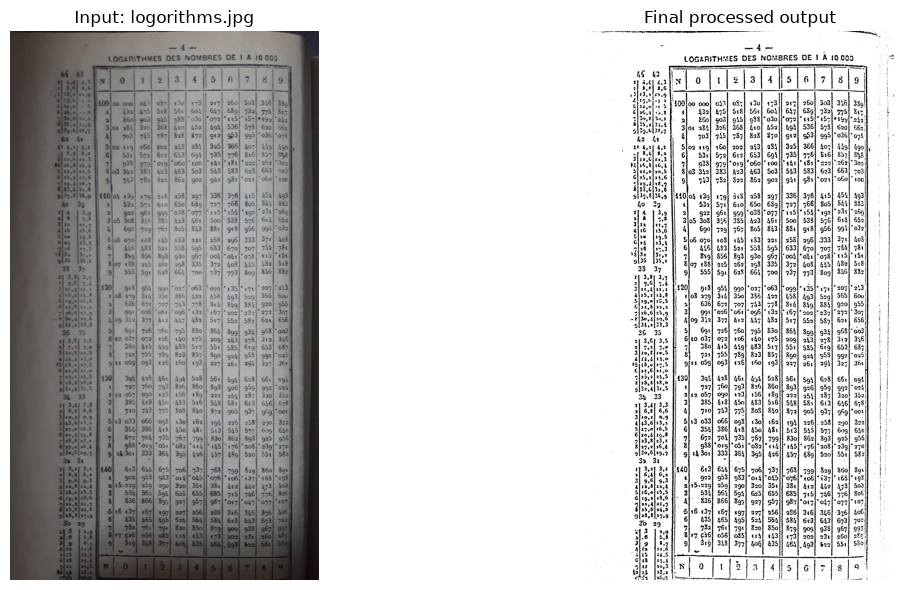

In [12]:
## Output Section

# This cell displays the selected input image and the final processed image directly here in the notebook.

input_rgb = cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB)
output_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(input_rgb)
axes[0].set_title(f"Input: {input_path.name}")
axes[0].axis("off")

axes[1].imshow(output_rgb)
axes[1].set_title("Final processed output")
axes[1].axis("off")

plt.tight_layout()
plt.show()
